## SmartServe - Food Waste Prediction and Decision Support System

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv("SmartServe_food_waste_dataset.csv")

print("First 5 rows:")
display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

First 5 rows:


,date,establishment_type,city,cuisine_type,food_item,item_category,meal_type,day_of_week,weather_condition,special_event,...,actual_customers,quantity_prepared,quantity_sold,leftover_quantity,waste_percentage,waste_reason,waste_risk,item_demand_share,planned_buffer_pct,forecast_error_pct
0,01-07-2025,Canteen,Ahmedabad,Gujarati,Khakhra,Snack,Breakfast,Tuesday,Sunny,Semester Break,...,203,43,43,0,0.00,No significant waste,Low,0.221,8.2,12.8
1,01-07-2025,Canteen,Ahmedabad,Gujarati,Masala Chai,Beverage,Breakfast,Tuesday,Sunny,Semester Break,...,203,100,100,0,0.00,No significant waste,Low,0.531,5.4,12.8
2,01-07-2025,Canteen,Ahmedabad,Gujarati,Poha,Breakfast Item,Breakfast,Tuesday,Sunny,Semester Break,...,203,80,80,0,0.00,No significant waste,Low,0.398,12.7,12.8
3,01-07-2025,Canteen,Ahmedabad,Gujarati,Gujarati Thali,Main Course,Lunch,Tuesday,Sunny,Semester Break,...,241,113,100,13,11.50,Overproduction (excess buffer),Medium,0.406,19.7,3.0
4,01-07-2025,Canteen,Ahmedabad,Gujarati,Khichdi Kadhi,Rice,Lunch,Tuesday,Sunny,Semester Break,...,241,85,73,12,14.12,Overproduction (excess buffer),Medium,0.304,19.2,3.0



Dataset Shape: (13248, 25)

Column Names:
['date', 'establishment_type', 'city', 'cuisine_type', 'food_item', 'item_category', 'meal_type', 'day_of_week', 'weather_condition', 'special_event', 'previous_day_sales', 'price_per_plate_inr', 'cost_per_plate_inr', 'discount_applied_pct', 'expected_customers', 'actual_customers', 'quantity_prepared', 'quantity_sold', 'leftover_quantity', 'waste_percentage', 'waste_reason', 'waste_risk', 'item_demand_share', 'planned_buffer_pct', 'forecast_error_pct']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 13248 entries, 0 to 13247
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   date                  13248 non-null  str    
 1   establishment_type    13248 non-null  str    
 2   city                  13248 non-null  str    
 3   cuisine_type          13248 non-null  str    
 4   food_item             13248 non-null  str    
 5   item_category    

In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("\nDataset Shape After Removing Duplicates:")
print(df.shape)

Missing Values:
date                    0
establishment_type      0
city                    0
cuisine_type            0
food_item               0
item_category           0
meal_type               0
day_of_week             0
weather_condition       0
special_event           0
previous_day_sales      0
price_per_plate_inr     0
cost_per_plate_inr      0
discount_applied_pct    0
expected_customers      0
actual_customers        0
quantity_prepared       0
quantity_sold           0
leftover_quantity       0
waste_percentage        0
waste_reason            0
waste_risk              0
item_demand_share       0
planned_buffer_pct      0
forecast_error_pct      0
dtype: int64

Duplicate Records:
0

Dataset Shape After Removing Duplicates:
(13248, 25)


In [4]:
df["date"] = pd.to_datetime(
    df["date"],
    dayfirst=True,
    errors="coerce"
)

print("Invalid dates:", df["date"].isna().sum())

df = df.dropna(subset=["date"]).reset_index(drop=True)

df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day

print("\nDate Conversion Completed:")
display(df[["date", "month", "day"]].head())

Invalid dates: 0

Date Conversion Completed:


,date,month,day
0,2025-07-01,7,1
1,2025-07-01,7,1
2,2025-07-01,7,1
3,2025-07-01,7,1
4,2025-07-01,7,1


In [5]:
invalid_sales = df[
    df["quantity_sold"] > df["quantity_prepared"]
]

print("Invalid Sales Records:", len(invalid_sales))

discount_col = ("discount_applied_pct"
    if "discount_applied_pct" in df.columns
    else "discount_applied"
)

invalid_discounts = df[
    (df[discount_col] < 0) |
    (df[discount_col] > 100)
]

print("Invalid Discount Records:", len(invalid_discounts))

negative_customers = df[
    (df["expected_customers"] < 0) |
    (df["actual_customers"] < 0)
]

print("Negative Customer Records:", len(negative_customers))

Invalid Sales Records: 0
Invalid Discount Records: 0
Negative Customer Records: 0


In [6]:
df = df[
    (df["quantity_sold"] <= df["quantity_prepared"]) &
    (df[discount_col] >= 0) &
    (df[discount_col] <= 100) &
    (df["expected_customers"] >= 0) &
    (df["actual_customers"] >= 0)
].copy()

df = df.reset_index(drop=True)

print("Dataset Shape After Removing Invalid Records:")
print(df.shape)

Dataset Shape After Removing Invalid Records:
(13248, 27)


In [7]:
pre_shift_features = [
    "date",
    "month",
    "day",
    "establishment_type",
    "city",
    "cuisine_type",
    "food_item",
    "item_category",
    "meal_type",
    "day_of_week",
    "weather_condition",
    "special_event",
    "previous_day_sales",
    "price_per_plate_inr",
    "cost_per_plate_inr",
    "discount_applied_pct",
    "expected_customers",
    "planned_buffer"
]

post_shift_outcomes = [
    "actual_customers",
    "quantity_prepared",
    "quantity_sold",
    "leftover_quantity",
    "waste_percentage",
    "waste_reason",
    "waste_risk",
    "item_demand",
    "forecast_error"
]

print("Available Pre-shift Features:")

print([
    col for col in pre_shift_features
    if col in df.columns
])

print("\nAvailable Post-shift Outcomes:")

print([
    col for col in post_shift_outcomes
    if col in df.columns
])

Available Pre-shift Features:
['date', 'month', 'day', 'establishment_type', 'city', 'cuisine_type', 'food_item', 'item_category', 'meal_type', 'day_of_week', 'weather_condition', 'special_event', 'previous_day_sales', 'price_per_plate_inr', 'cost_per_plate_inr', 'discount_applied_pct', 'expected_customers']

Available Post-shift Outcomes:
['actual_customers', 'quantity_prepared', 'quantity_sold', 'leftover_quantity', 'waste_percentage', 'waste_reason', 'waste_risk']


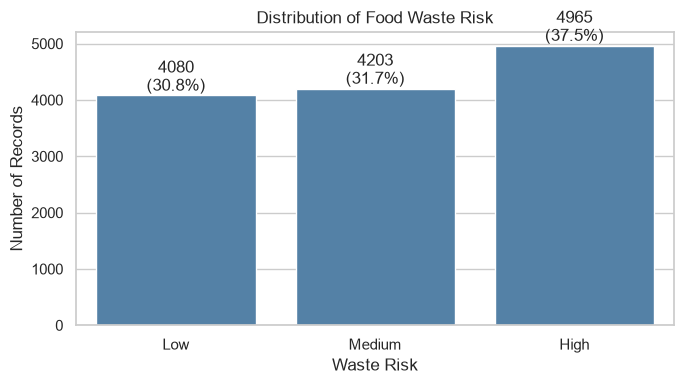

In [8]:
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df,
    x="waste_risk",
    order=["Low", "Medium", "High"],
    color="steelblue"
)

plt.title("Distribution of Food Waste Risk")
plt.xlabel("Waste Risk")
plt.ylabel("Number of Records")

total = len(df)

for p in ax.patches:
    count = int(p.get_height())
    percentage = count / total * 100

    ax.annotate(
        f"{count}\n({percentage:.1f}%)",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

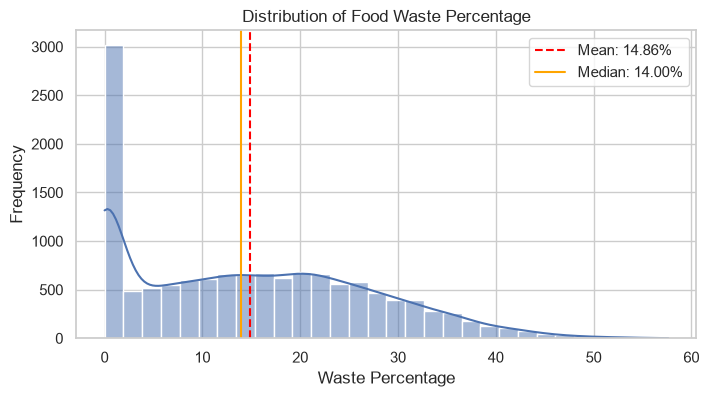

In [9]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="waste_percentage",
    kde=True,
    bins=30
)

mean_waste = df["waste_percentage"].mean()
median_waste = df["waste_percentage"].median()

plt.axvline(
    mean_waste,
    color="red",
    linestyle="--",
    label=f"Mean: {mean_waste:.2f}%"
)

plt.axvline(
    median_waste,
    color="orange",
    linestyle="-",
    label=f"Median: {median_waste:.2f}%"
)

plt.title("Distribution of Food Waste Percentage")
plt.xlabel("Waste Percentage")
plt.ylabel("Frequency")
plt.legend()

plt.show()

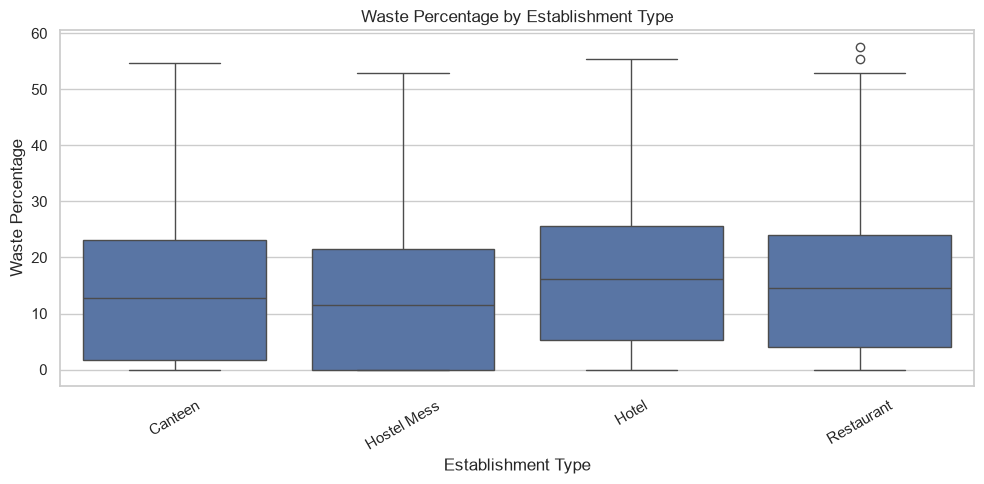

In [10]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="establishment_type",
    y="waste_percentage"
)

plt.title("Waste Percentage by Establishment Type")
plt.xlabel("Establishment Type")
plt.ylabel("Waste Percentage")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

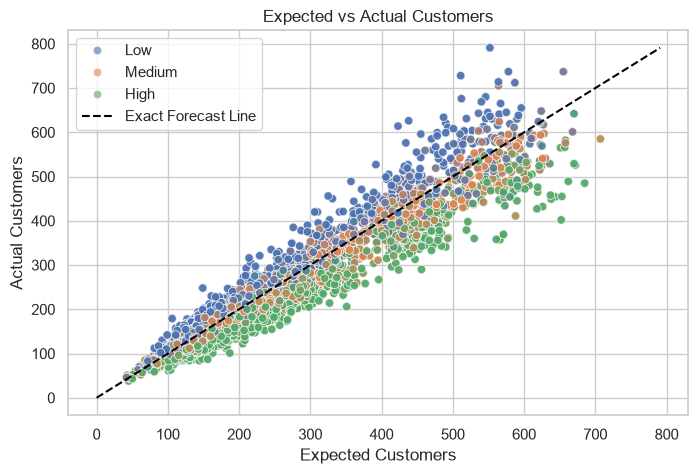

In [11]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="expected_customers",
    y="actual_customers",
    hue="waste_risk",
    hue_order=["Low", "Medium", "High"],
    alpha=0.6
)

max_customers = max(
    df["expected_customers"].max(),
    df["actual_customers"].max()
)

plt.plot(
    [0, max_customers],
    [0, max_customers],
    color="black",
    linestyle="--",
    label="Exact Forecast Line"
)

plt.title("Expected vs Actual Customers")
plt.xlabel("Expected Customers")
plt.ylabel("Actual Customers")

plt.legend()
plt.show()

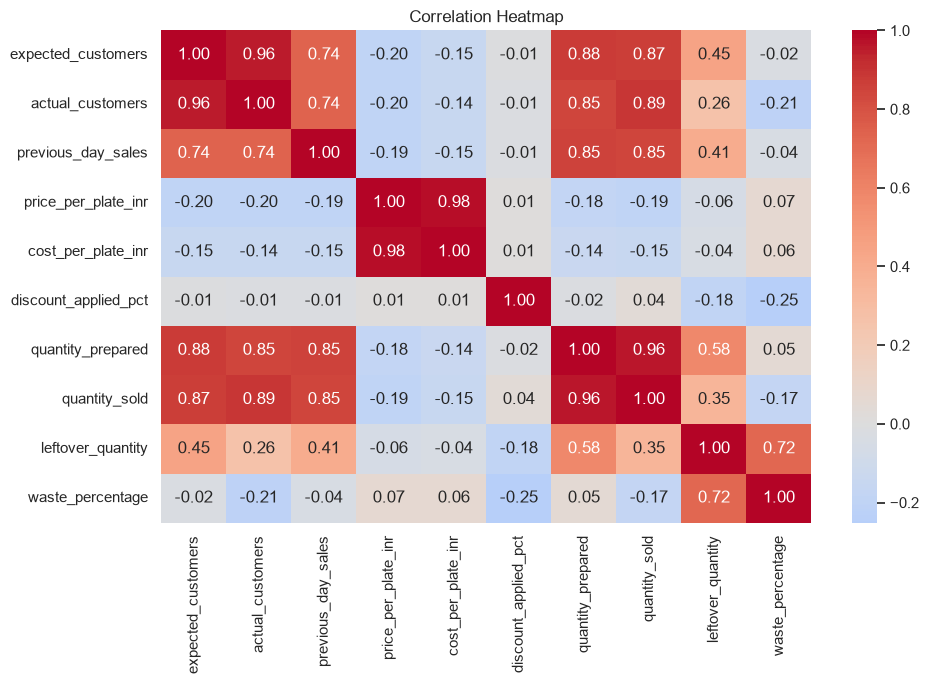

In [12]:
numeric_features = [
    "expected_customers",
    "actual_customers",
    "previous_day_sales",
    "price_per_plate_inr",
    "cost_per_plate_inr",
    "discount_applied_pct",
    "quantity_prepared",
    "quantity_sold",
    "leftover_quantity",
    "waste_percentage"
]

numeric_features = [
    col for col in numeric_features
    if col in df.columns
]

corr_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
numerical_cols = [
    "previous_day_sales",
    "price_per_plate_inr",
    "cost_per_plate_inr",
    "discount_applied_pct",
    "expected_customers",
    "planned_buffer"
]

numerical_cols = [
    col for col in numerical_cols
    if col in df.columns
]

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outlier_mask = (
    (df[numerical_cols] < lower_bound) |
    (df[numerical_cols] > upper_bound)
).any(axis=1)

df_cleaned = df.loc[~outlier_mask].copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_cleaned.shape)
print("Total Outlier Records Removed:", outlier_mask.sum())

Original Dataset Shape: (13248, 27)
Cleaned Dataset Shape: (9618, 27)
Total Outlier Records Removed: 3630


In [14]:
file_path = "smartserve_cleaned_data_phase02.csv"

df_cleaned.to_csv(file_path, index=False)

print("Cleaned Dataset Successfully Saved!")
print("File Name:", file_path)
print("Final Dataset Shape:", df_cleaned.shape)

Cleaned Dataset Successfully Saved!
File Name: smartserve_cleaned_data_phase02.csv
Final Dataset Shape: (9618, 27)


## UNIT 2

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [16]:
df = pd.read_csv("smartserve_cleaned_data_phase02.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nTarget Distribution:")
print(df["waste_risk"].value_counts())

Dataset Shape: (9618, 27)


,date,establishment_type,city,cuisine_type,food_item,item_category,meal_type,day_of_week,weather_condition,special_event,...,quantity_sold,leftover_quantity,waste_percentage,waste_reason,waste_risk,item_demand_share,planned_buffer_pct,forecast_error_pct,month,day
0,2025-07-01,Canteen,Ahmedabad,Gujarati,Khakhra,Snack,Breakfast,Tuesday,Sunny,Semester Break,...,43,0,0.00,No significant waste,Low,0.221,8.2,12.8,7,1
1,2025-07-01,Canteen,Ahmedabad,Gujarati,Masala Chai,Beverage,Breakfast,Tuesday,Sunny,Semester Break,...,100,0,0.00,No significant waste,Low,0.531,5.4,12.8,7,1
2,2025-07-01,Canteen,Ahmedabad,Gujarati,Poha,Breakfast Item,Breakfast,Tuesday,Sunny,Semester Break,...,80,0,0.00,No significant waste,Low,0.398,12.7,12.8,7,1
3,2025-07-01,Canteen,Ahmedabad,Gujarati,Gujarati Thali,Main Course,Lunch,Tuesday,Sunny,Semester Break,...,100,13,11.50,Overproduction (excess buffer),Medium,0.406,19.7,3.0,7,1
4,2025-07-01,Canteen,Ahmedabad,Gujarati,Khichdi Kadhi,Rice,Lunch,Tuesday,Sunny,Semester Break,...,73,12,14.12,Overproduction (excess buffer),Medium,0.304,19.2,3.0,7,1



Target Distribution:
waste_risk
High      3924
Medium    3152
Low       2542
Name: count, dtype: int64


In [17]:
TARGET_COLUMN = "waste_risk"

leakage_columns = [
    "date",
    "actual_customers",
    "quantity_prepared",
    "quantity_sold",
    "leftover_quantity",
    "waste_percentage",
    "waste_reason",
    "item_demand",
    "forecast_error"
]

df = df.drop(
    columns=[
        col for col in leakage_columns
        if col in df.columns
    ]
)

X_raw = df.drop(columns=[TARGET_COLUMN])

y = df[TARGET_COLUMN]

print("Prediction Features:")
print(X_raw.columns.tolist())

print("\nTarget Variable:", y.name)

print("\nTarget Distribution:")
print(y.value_counts())

Prediction Features:
['establishment_type', 'city', 'cuisine_type', 'food_item', 'item_category', 'meal_type', 'day_of_week', 'weather_condition', 'special_event', 'previous_day_sales', 'price_per_plate_inr', 'cost_per_plate_inr', 'discount_applied_pct', 'expected_customers', 'item_demand_share', 'planned_buffer_pct', 'forecast_error_pct', 'month', 'day']

Target Variable: waste_risk

Target Distribution:
waste_risk
High      3924
Medium    3152
Low       2542
Name: count, dtype: int64


In [18]:
def add_smartserve_features(data):

    data = data.copy()

    if "day_of_week" in data.columns:

        data["is_weekend"] = data[
            "day_of_week"
        ].isin(["Saturday", "Sunday"]).astype(int)

    if (
        "planned_buffer" in data.columns and
        "expected_customers" in data.columns
    ):

        data["expected_total_prep"] = (
            data["expected_customers"] +
            data["planned_buffer"]
        )

        data["buffer_to_expected_ratio"] = (
            data["planned_buffer"] /
            (data["expected_customers"] + 1)
        )

    if (
        "expected_customers" in data.columns and
        "previous_day_sales" in data.columns
    ):

        data["sales_vs_expected_diff"] = (
            data["expected_customers"] -
            data["previous_day_sales"]
        )

    if (
        "price_per_plate_inr" in data.columns and
        "cost_per_plate_inr" in data.columns
    ):

        data["profit_margin_inr"] = (
            data["price_per_plate_inr"] -
            data["cost_per_plate_inr"]
        )

        data["margin_percentage"] = (
            data["profit_margin_inr"] /
            (data["price_per_plate_inr"] + 1)
        ) * 100

    return data


X = add_smartserve_features(X_raw)

print("Features After Engineering:", X.shape[1])

print("\nFinal Feature Columns:")
print(X.columns.tolist())

Features After Engineering: 23

Final Feature Columns:
['establishment_type', 'city', 'cuisine_type', 'food_item', 'item_category', 'meal_type', 'day_of_week', 'weather_condition', 'special_event', 'previous_day_sales', 'price_per_plate_inr', 'cost_per_plate_inr', 'discount_applied_pct', 'expected_customers', 'item_demand_share', 'planned_buffer_pct', 'forecast_error_pct', 'month', 'day', 'is_weekend', 'sales_vs_expected_diff', 'profit_margin_inr', 'margin_percentage']


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", X_train.shape[0])

print("Testing Records:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training Records: 7694
Testing Records: 1924

Training Class Distribution:
waste_risk
High      0.408
Medium    0.328
Low       0.264
Name: proportion, dtype: float64

Testing Class Distribution:
waste_risk
High      0.408
Medium    0.328
Low       0.264
Name: proportion, dtype: float64


In [20]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['previous_day_sales', 'price_per_plate_inr', 'cost_per_plate_inr', 'discount_applied_pct', 'expected_customers', 'item_demand_share', 'planned_buffer_pct', 'forecast_error_pct', 'month', 'day', 'is_weekend', 'sales_vs_expected_diff', 'profit_margin_inr', 'margin_percentage']

Categorical Features:
['establishment_type', 'city', 'cuisine_type', 'food_item', 'item_category', 'meal_type', 'day_of_week', 'weather_condition', 'special_event']


In [21]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully.")

Preprocessing Pipeline Created Successfully.


In [22]:
def evaluate_model(name, model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    try:

        y_proba = model.predict_proba(X_test)

        roc_auc = roc_auc_score(
            y_test,
            y_proba,
            labels=model.classes_,
            multi_class="ovr",
            average="weighted"
        )

    except Exception:

        roc_auc = np.nan

    print("\n" + "=" * 50)
    print("Model:", name)
    print("=" * 50)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(roc_auc, 4))
    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            zero_division=0
        )
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1_Score": f1,
        "ROC_AUC": roc_auc,
        "y_pred": y_pred,
        "trained_model": model
    }

In [23]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", DummyClassifier(
        strategy="most_frequent"
    ))
])

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Baseline Model Performance")
print("Accuracy:",
      accuracy_score(y_test, y_pred_baseline))
print("Precision:",
      precision_score(
          y_test, y_pred_baseline,
          average="weighted",
          zero_division=0
      ))
print("Recall:",
      recall_score(
          y_test, y_pred_baseline,
          average="weighted",
          zero_division=0
      ))
print("F1 Score:",
      f1_score(
          y_test, y_pred_baseline,
          average="weighted",
          zero_division=0
      ))

Baseline Model Performance
Accuracy: 0.408004158004158
Precision: 0.16646739294868196
Recall: 0.408004158004158
F1 Score: 0.23645866669122484


In [24]:
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", DecisionTreeClassifier(
        random_state=42,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced"
    ))
])

dt_result = evaluate_model(
    "Decision Tree",
    decision_tree_model,
    X_train, X_test, y_train, y_test
)


Model: Decision Tree
Accuracy: 0.9018
Precision: 0.9025
Recall: 0.9018
F1 Score: 0.9021
ROC-AUC: 0.9579

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.93      0.94       785
         Low       0.90      0.91      0.91       508
      Medium       0.85      0.86      0.85       631

    accuracy                           0.90      1924
   macro avg       0.90      0.90      0.90      1924
weighted avg       0.90      0.90      0.90      1924



In [25]:
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=18,
        max_features=0.5,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

rf_result = evaluate_model(
    "Random Forest",
    random_forest_model,
    X_train, X_test, y_train, y_test
)


Model: Random Forest
Accuracy: 0.9304
Precision: 0.9314
Recall: 0.9304
F1 Score: 0.9307
ROC-AUC: 0.9906

Classification Report:
              precision    recall  f1-score   support

        High       0.97      0.94      0.96       785
         Low       0.92      0.94      0.93       508
      Medium       0.88      0.91      0.90       631

    accuracy                           0.93      1924
   macro avg       0.93      0.93      0.93      1924
weighted avg       0.93      0.93      0.93      1924



In [26]:
import joblib

# Save the trained Random Forest model
joblib.dump(random_forest_model, "smartserve_final_model.pkl")

print("SmartServe Random Forest model saved successfully!")

SmartServe Random Forest model saved successfully!


In [27]:
import joblib

final_model = joblib.load("smartserve_final_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [28]:
knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", KNeighborsClassifier(
        n_neighbors=15,
        weights="distance",
        metric="manhattan"
    ))
])

knn_result = evaluate_model(
    "KNN",
    knn_model,
    X_train, X_test, y_train, y_test
)


Model: KNN
Accuracy: 0.6237
Precision: 0.6347
Recall: 0.6237
F1 Score: 0.6241
ROC-AUC: 0.8023

Classification Report:
              precision    recall  f1-score   support

        High       0.71      0.76      0.74       785
         Low       0.73      0.53      0.61       508
      Medium       0.47      0.52      0.49       631

    accuracy                           0.62      1924
   macro avg       0.63      0.61      0.61      1924
weighted avg       0.63      0.62      0.62      1924



In [29]:
unit2_results = pd.DataFrame([

    {
        "Model": "Baseline",
        "Accuracy": accuracy_score(y_test, y_pred_baseline),
        "Precision": precision_score(
            y_test, y_pred_baseline,
            average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_baseline,
            average="weighted", zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, y_pred_baseline,
            average="weighted", zero_division=0
        ),
        "ROC_AUC": np.nan
    },

    {
        "Model": dt_result["Model"],
        "Accuracy": dt_result["Accuracy"],
        "Precision": dt_result["Precision"],
        "Recall": dt_result["Recall"],
        "F1_Score": dt_result["F1_Score"],
        "ROC_AUC": dt_result["ROC_AUC"]
    },

    {
        "Model": rf_result["Model"],
        "Accuracy": rf_result["Accuracy"],
        "Precision": rf_result["Precision"],
        "Recall": rf_result["Recall"],
        "F1_Score": rf_result["F1_Score"],
        "ROC_AUC": rf_result["ROC_AUC"]
    },

    {
        "Model": knn_result["Model"],
        "Accuracy": knn_result["Accuracy"],
        "Precision": knn_result["Precision"],
        "Recall": knn_result["Recall"],
        "F1_Score": knn_result["F1_Score"],
        "ROC_AUC": knn_result["ROC_AUC"]
    }

])

unit2_results = unit2_results.round(4)

display(unit2_results)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Baseline,0.4080,0.1665,0.4080,0.2365,NaN
1,Decision Tree,0.9018,0.9025,0.9018,0.9021,0.9579
2,Random Forest,0.9304,0.9314,0.9304,0.9307,0.9906
3,KNN,0.6237,0.6347,0.6237,0.6241,0.8023


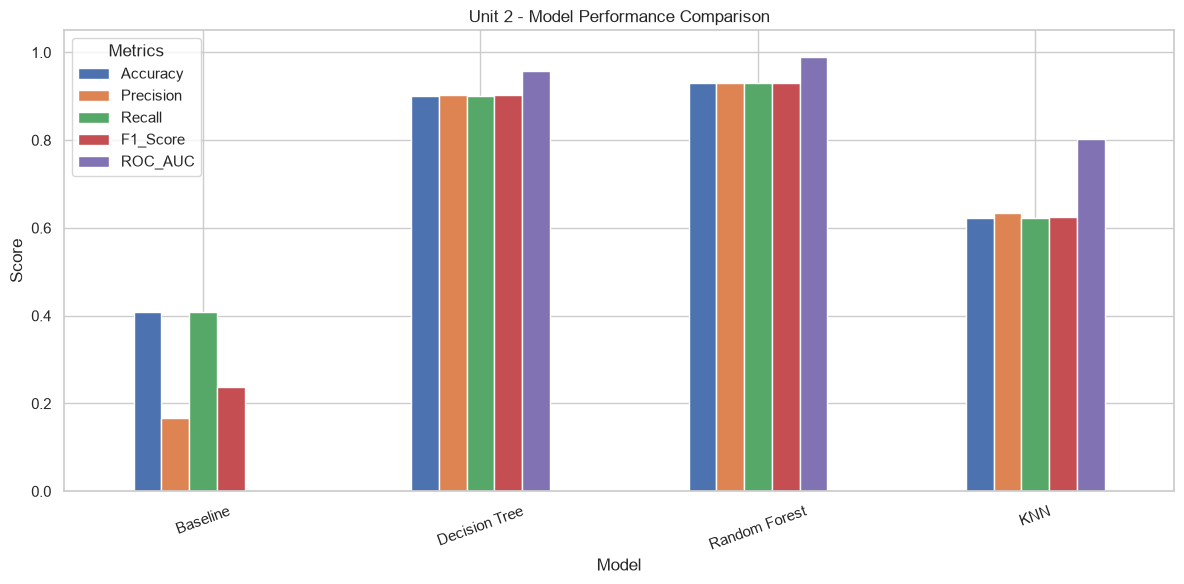

In [30]:
unit2_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Unit 2 - Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

Normalized Confusion Matrix Visualization


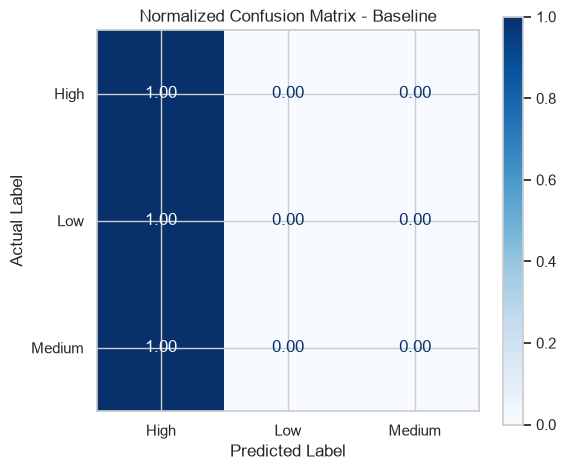

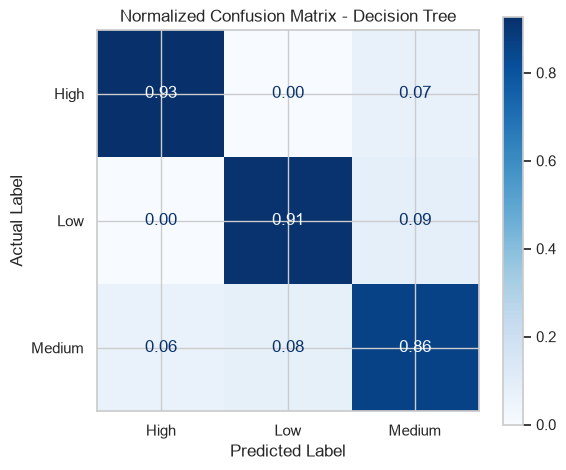

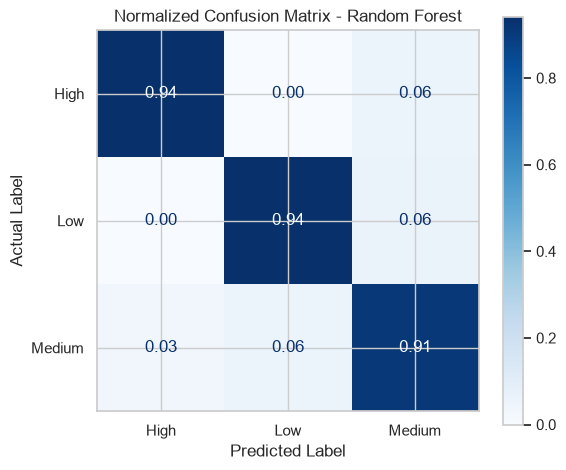

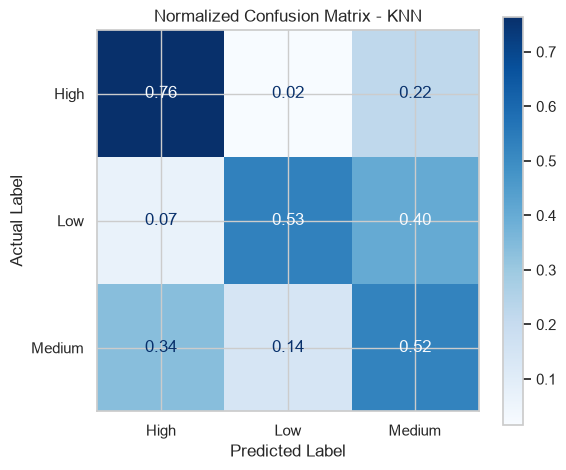

In [31]:
from sklearn.metrics import ConfusionMatrixDisplay

# Define model predictions dictionary
model_predictions = {
    "Baseline": y_pred_baseline,
    "Decision Tree": dt_result["y_pred"],
    "Random Forest": rf_result["y_pred"],
    "KNN": knn_result["y_pred"]
}

# Define class labels
class_labels = np.unique(y_test)

print("Normalized Confusion Matrix Visualization")
print("=" * 60)

for model_name, y_pred in model_predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels,
        normalize="true"
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=True,
        values_format=".2f"
    )

    ax.set_title(f"Normalized Confusion Matrix - {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

    plt.tight_layout()
    plt.show()

## UNIT 3

In [32]:
from sklearn.model_selection import GridSearchCV

In [33]:
dt_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

dt_param_grid = {

    "classifier__max_depth": [8, 10, 15],

    "classifier__min_samples_split": [5, 10],

    "classifier__min_samples_leaf": [2, 5]

}

dt_grid = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=dt_param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree Parameters:")
print(dt_grid.best_params_)
print("\nBest Cross Validation F1 Score:")
print(round(dt_grid.best_score_, 4))

Best Decision Tree Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 5}

Best Cross Validation F1 Score:
0.9038


In [34]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced_subsample",
        n_jobs=1
    ))
])

rf_param_grid = {

    "classifier__n_estimators": [200, 300],

    "classifier__max_depth": [12, 18],

    "classifier__min_samples_leaf": [2, 4]

}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)
print("\nBest Cross Validation F1 Score:")
print(round(rf_grid.best_score_, 4))

Best Random Forest Parameters:
{'classifier__max_depth': 18, 'classifier__min_samples_leaf': 2, 'classifier__n_estimators': 300}

Best Cross Validation F1 Score:
0.8397


In [35]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", KNeighborsClassifier())
])

knn_param_grid = {

    "classifier__n_neighbors": [5, 11, 15],

    "classifier__weights": ["uniform", "distance"],

    "classifier__metric": ["manhattan"]

}

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=3,
    scoring="f1_weighted",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:")
print(knn_grid.best_params_)
print("\nBest Cross Validation F1 Score:")
print(round(knn_grid.best_score_, 4))

Best KNN Parameters:
{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}

Best Cross Validation F1 Score:
0.604


In [36]:
best_dt_model = dt_grid.best_estimator_

dt_tuned_result = evaluate_model(
    "Tuned Decision Tree",
    best_dt_model,
    X_train, X_test, y_train, y_test
)


Model: Tuned Decision Tree
Accuracy: 0.9018
Precision: 0.9025
Recall: 0.9018
F1 Score: 0.9021
ROC-AUC: 0.9579

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.93      0.94       785
         Low       0.90      0.91      0.91       508
      Medium       0.85      0.86      0.85       631

    accuracy                           0.90      1924
   macro avg       0.90      0.90      0.90      1924
weighted avg       0.90      0.90      0.90      1924



In [37]:
best_rf_model = rf_grid.best_estimator_

rf_tuned_result = evaluate_model(
    "Tuned Random Forest"
    ,
    best_rf_model,
    X_train, X_test, y_train, y_test
)


Model: Tuned Random Forest
Accuracy: 0.8477
Precision: 0.8471
Recall: 0.8477
F1 Score: 0.8474
ROC-AUC: 0.9569

Classification Report:
              precision    recall  f1-score   support

        High       0.90      0.91      0.90       785
         Low       0.86      0.86      0.86       508
      Medium       0.78      0.76      0.77       631

    accuracy                           0.85      1924
   macro avg       0.84      0.84      0.84      1924
weighted avg       0.85      0.85      0.85      1924



In [38]:
best_knn_model = knn_grid.best_estimator_

knn_tuned_result = evaluate_model(
    "Tuned KNN",
    best_knn_model,
    X_train, X_test, y_train, y_test
)


Model: Tuned KNN
Accuracy: 0.6237
Precision: 0.6347
Recall: 0.6237
F1 Score: 0.6241
ROC-AUC: 0.8023

Classification Report:
              precision    recall  f1-score   support

        High       0.71      0.76      0.74       785
         Low       0.73      0.53      0.61       508
      Medium       0.47      0.52      0.49       631

    accuracy                           0.62      1924
   macro avg       0.63      0.61      0.61      1924
weighted avg       0.63      0.62      0.62      1924



In [39]:
unit3_results = pd.DataFrame([

    {
        "Model": dt_tuned_result["Model"],
        "Accuracy": dt_tuned_result["Accuracy"],
        "Precision": dt_tuned_result["Precision"],
        "Recall": dt_tuned_result["Recall"],
        "F1_Score": dt_tuned_result["F1_Score"],
        "ROC_AUC": dt_tuned_result["ROC_AUC"]
    },

    {
        "Model": rf_tuned_result["Model"],
        "Accuracy": rf_tuned_result["Accuracy"],
        "Precision": rf_tuned_result["Precision"],
        "Recall": rf_tuned_result["Recall"],
        "F1_Score": rf_tuned_result["F1_Score"],
        "ROC_AUC": rf_tuned_result["ROC_AUC"]
    },

    {
        "Model": knn_tuned_result["Model"],
        "Accuracy": knn_tuned_result["Accuracy"],
        "Precision": knn_tuned_result["Precision"],
        "Recall": knn_tuned_result["Recall"],
        "F1_Score": knn_tuned_result["F1_Score"],
        "ROC_AUC": knn_tuned_result["ROC_AUC"]
    }

])

unit3_results = unit3_results.round(4)

print("Unit 3 - Tuned Model Comparison")
display(unit3_results)

Unit 3 - Tuned Model Comparison


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Tuned Decision Tree,0.9018,0.9025,0.9018,0.9021,0.9579
1,Tuned Random Forest,0.8477,0.8471,0.8477,0.8474,0.9569
2,Tuned KNN,0.6237,0.6347,0.6237,0.6241,0.8023


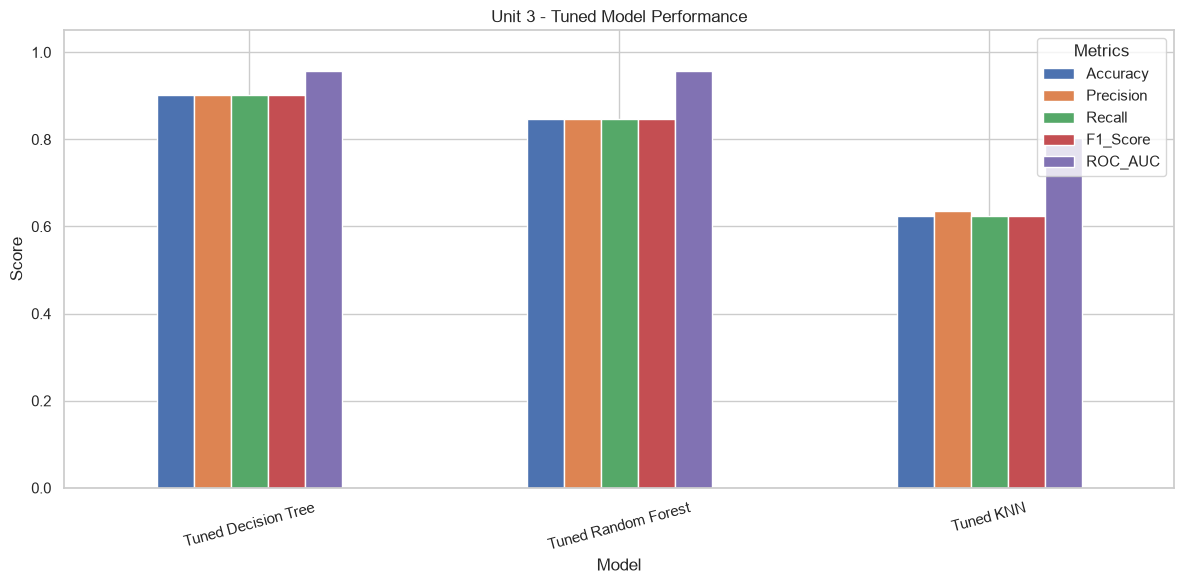

In [40]:
unit3_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1_Score", "ROC_AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Unit 3 - Tuned Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

In [41]:
best_model_row = unit3_results.loc[
    unit3_results["F1_Score"].idxmax()
]

best_model_name = best_model_row["Model"]

print("Best Model Based on Weighted F1 Score:")
print(best_model_name)
print("\nBest Weighted F1 Score:")
print(best_model_row["F1_Score"])

Best Model Based on Weighted F1 Score:
Tuned Decision Tree

Best Weighted F1 Score:
0.9021


In [42]:
final_models = {
    "Tuned Decision Tree": best_dt_model,
    "Tuned Random Forest": best_rf_model,
    "Tuned KNN": best_knn_model
}

print("High Risk Class Performance:\n")

for name, model in final_models.items():

    predictions = model.predict(X_test)

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    print(name)
    print(
        "High Risk Recall:",
        round(report.get("High", {}).get("recall", 0), 4)
    )
    print(
        "High Risk F1 Score:",
        round(report.get("High", {}).get("f1-score", 0), 4)
    )
    print("-" * 40)

High Risk Class Performance:

Tuned Decision Tree
High Risk Recall: 0.9274
High Risk F1 Score: 0.9381
----------------------------------------
Tuned Random Forest
High Risk Recall: 0.9057
High Risk F1 Score: 0.9017
----------------------------------------
Tuned KNN
High Risk Recall: 0.7643
High Risk F1 Score: 0.7357
----------------------------------------


## UNIT 4

In [43]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.base import clone

In [44]:
cluster_preprocessor = clone(preprocessor)

X_cluster = cluster_preprocessor.fit_transform(X_train)

print("Clustering Data Prepared Successfully")
print("Training Data Shape:", X_cluster.shape)

Clustering Data Prepared Successfully
Training Data Shape: (7694, 118)


In [45]:
inertia_values = []

for k in range(2, 7):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster)

    inertia_values.append(kmeans.inertia_)

print("Inertia Values:")
print(inertia_values)

Inertia Values:
[133241.76049609677, 120478.4912026274, 113364.75162159873, 108906.81025081321, 105382.65762151963]


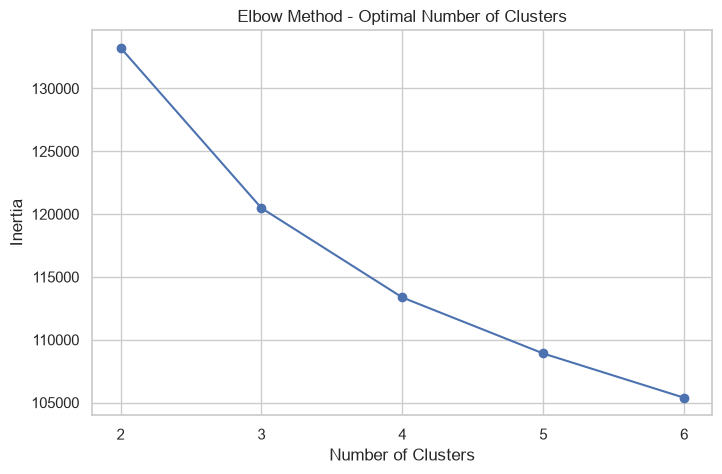

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 7),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method - Optimal Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(range(2, 7))
plt.grid(True)
plt.show()

In [47]:
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans_model.fit_predict(X_cluster)

print("K-Means Clustering Completed")
print("\nCluster Distribution:")
print(
    pd.Series(cluster_labels)
    .value_counts()
    .sort_index()
)

K-Means Clustering Completed

Cluster Distribution:
0    2230
1    3634
2    1830
Name: count, dtype: int64


In [48]:
cluster_results = X_train.copy()

cluster_results["Cluster"] = cluster_labels

cluster_results["waste_risk"] = y_train.values

display(cluster_results.head())

,establishment_type,city,cuisine_type,food_item,item_category,meal_type,day_of_week,weather_condition,special_event,previous_day_sales,...,planned_buffer_pct,forecast_error_pct,month,day,is_weekend,sales_vs_expected_diff,profit_margin_inr,margin_percentage,Cluster,waste_risk
8749,Canteen,Surat,Street Food,Pani Puri,Snack,Snacks,Tuesday,Cloudy,No Event,76,...,19.8,9.5,12,16,0,176,16.43,63.192308,2,Medium
7325,Restaurant,Delhi,Chinese,Schezwan Fried Rice,Rice,Dinner,Monday,Cloudy,No Event,83,...,12.4,-21.8,11,17,0,64,130.72,70.279570,0,High
6545,Hostel Mess,Bengaluru,Multi-cuisine,Buttermilk,Beverage,Lunch,Sunday,Sunny,No Event,144,...,4.9,-12.1,11,2,1,261,7.50,68.181818,2,Medium
4901,Hostel Mess,Delhi,North Indian,Lassi,Beverage,Breakfast,Wednesday,Rainy,Navratri,92,...,11.4,14.1,10,1,0,206,22.38,72.193548,2,Low
2892,Hotel,Jaipur,North Indian,Chole Bhature,Breakfast Item,Breakfast,Sunday,Sunny,Cricket Match,68,...,14.8,20.7,8,24,1,101,99.84,66.119205,0,Low


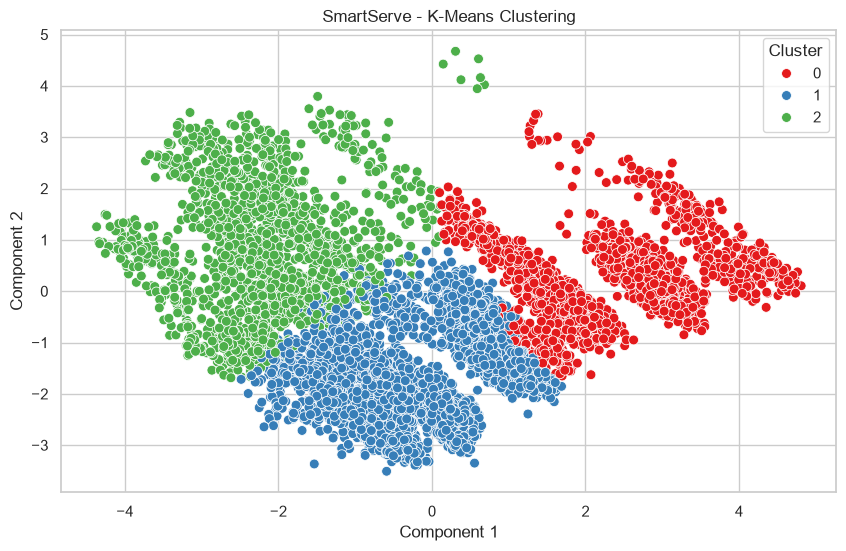

In [49]:
svd = TruncatedSVD(
    n_components=2,
    random_state=42
)

X_reduced = svd.fit_transform(X_cluster)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_reduced[:, 0],
    y=X_reduced[:, 1],
    hue=cluster_labels,
    palette="Set1",
    s=50
)

plt.title("SmartServe - K-Means Clustering")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.legend(title="Cluster")
plt.show()

In [50]:
numeric_columns = cluster_results.select_dtypes(
    include=np.number
).columns.tolist()

numeric_columns.remove("Cluster")

cluster_analysis = cluster_results.groupby(
    "Cluster"
)[numeric_columns].mean()

print("Cluster Characteristics:")
display(cluster_analysis.round(2))

Cluster Characteristics:


,previous_day_sales,price_per_plate_inr,cost_per_plate_inr,discount_applied_pct,expected_customers,item_demand_share,planned_buffer_pct,forecast_error_pct,month,day,is_weekend,sales_vs_expected_diff,profit_margin_inr,margin_percentage
Cluster,,,,,,,,,,,,,,
0,54.73,138.35,43.73,0.0,161.04,0.35,16.46,-3.38,9.47,15.85,0.29,106.31,94.62,67.52
1,61.31,41.30,12.52,0.0,151.07,0.40,14.27,-3.01,9.54,16.33,0.34,89.76,28.78,68.06
2,103.63,37.19,13.31,0.0,332.24,0.35,10.94,-4.28,9.31,15.06,0.23,228.61,23.89,63.55


In [51]:
risk_analysis = pd.crosstab(
    cluster_results["Cluster"],
    cluster_results["waste_risk"],
    normalize="index"
) * 100

print("Waste Risk Distribution Across Clusters:")
display(risk_analysis.round(2))

Waste Risk Distribution Across Clusters:


waste_risk,High,Low,Medium
Cluster,,,
0,44.93,22.24,32.83
1,40.56,26.50,32.94
2,36.23,31.42,32.35


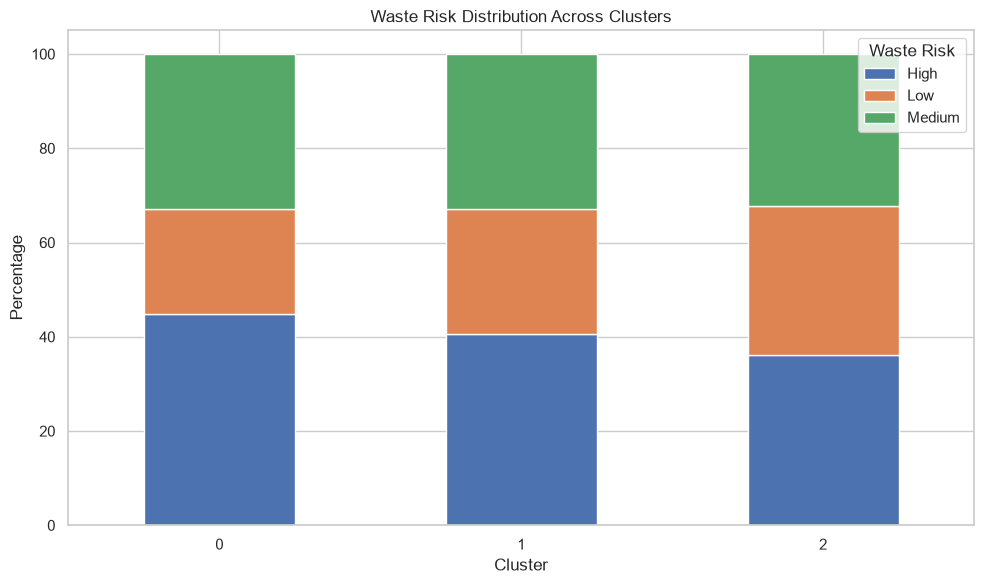

In [52]:
risk_analysis.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Waste Risk Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Waste Risk")
plt.tight_layout()
plt.show()

## PREDICTION 

In [53]:
# import joblib

# final_model = joblib.load("smartserve_final_model.pkl")

# print("Model loaded successfully!")

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("SmartServe_food_waste_dataset.csv")
X = df.drop("waste_risk", axis=1)

unseen_input = {}

for col in X.columns:
    if pd.api.types.is_numeric_dtype(X[col]):
        unseen_input[col] = X[col].median()
    else:
        unseen_input[col] = X[col].mode().iloc[0]

unseen_data = pd.DataFrame([unseen_input])

## MAKE CHANGES FOR NEW PREDICTION

In [59]:
unseen_data.loc[0, "establishment_type"] = "Hotel"
unseen_data.loc[0, "city"] = "Ahmedabad"
unseen_data.loc[0, "cuisine_type"] = "Indian"
unseen_data.loc[0, "food_item"] = "Pizza"
unseen_data.loc[0, "item_category"] = "Main Course"
unseen_data.loc[0, "meal_type"] = "Lunch"
unseen_data.loc[0, "day_of_week"] = "Sunday"
unseen_data.loc[0, "weather_condition"] = "Sunny"
unseen_data.loc[0, "special_event"] = "Yes"
unseen_data.loc[0, "previous_day_sales"] = 100
unseen_data.loc[0, "expected_customers"] = 180
unseen_data.loc[0, "price_per_plate_inr"] = 180
unseen_data.loc[0, "cost_per_plate_inr"] = 130
unseen_data.loc[0, "discount_applied_pct"] = 0
unseen_data.loc[0, "planned_buffer"] = 20

SMARTSERVE FOOD WASTE PREDICTION
--------------------------------
Selected Final Model: Untuned Random Forest
Establishment: Hotel
Food Item: Pizza
Meal Type: Lunch

Predicted Waste Risk: Medium


,Waste Risk,Probability (%)
0,High,20.96
1,Low,1.91
2,Medium,77.13


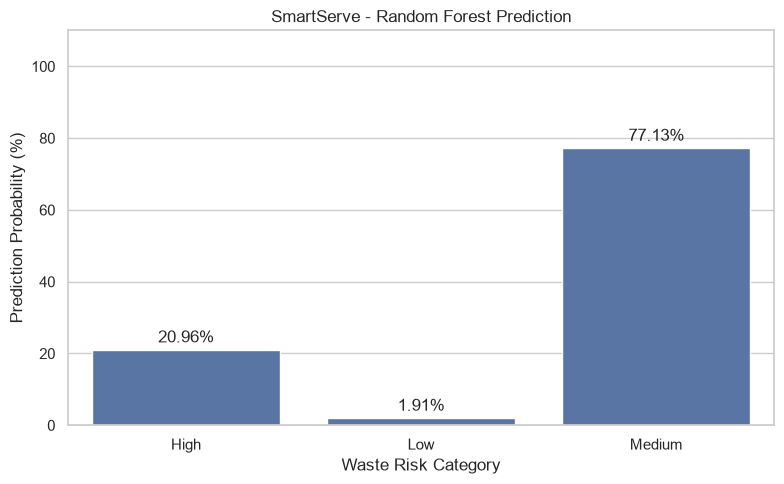

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# STEP 1: DEFINE UNTUNED RANDOM FOREST MODEL
# ==========================================

final_model = random_forest_model


# ==========================================
# STEP 2: CREATE ADDITIONAL FEATURES
# ==========================================

unseen_data["margin_percentage"] = (
    (unseen_data["price_per_plate_inr"] -
     unseen_data["cost_per_plate_inr"]) /
    unseen_data["price_per_plate_inr"].replace(0, 1)
) * 100

unseen_data["profit_margin_inr"] = (
    unseen_data["price_per_plate_inr"] -
    unseen_data["cost_per_plate_inr"]
)

unseen_data["sales_vs_expected_diff"] = (
    unseen_data["expected_customers"] -
    unseen_data["previous_day_sales"]
)

unseen_data["is_weekend"] = (
    unseen_data["day_of_week"]
    .isin(["Saturday", "Sunday"])
).astype(int)

unseen_data["day"] = 30
unseen_data["month"] = 10


# ==========================================
# STEP 3: SELECT REQUIRED FEATURES
# ==========================================

required_columns = final_model.named_steps[
    "preprocessor"
].feature_names_in_

unseen_features = unseen_data[
    list(required_columns)
].copy()


# ==========================================
# STEP 4: MAKE PREDICTION
# ==========================================

prediction = final_model.predict(unseen_features)

prediction_probabilities = final_model.predict_proba(
    unseen_features
)

predicted_risk = prediction[0]


# ==========================================
# STEP 5: DISPLAY PREDICTION
# ==========================================

print("SMARTSERVE FOOD WASTE PREDICTION")
print("--------------------------------")

print("Selected Final Model: Untuned Random Forest")

print("Establishment:",
      unseen_data.loc[0, "establishment_type"])

print("Food Item:",
      unseen_data.loc[0, "food_item"])

print("Meal Type:",
      unseen_data.loc[0, "meal_type"])

print("\nPredicted Waste Risk:", predicted_risk)


# ==========================================
# STEP 6: DISPLAY PROBABILITIES
# ==========================================

probability_df = pd.DataFrame({
    "Waste Risk": final_model.classes_,
    "Probability (%)": (
        prediction_probabilities[0] * 100
    ).round(2)
})

display(probability_df)


# ==========================================
# STEP 7: VISUALIZE PREDICTION
# ==========================================

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=probability_df,
    x="Waste Risk",
    y="Probability (%)"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("SmartServe - Random Forest Prediction")
plt.xlabel("Waste Risk Category")
plt.ylabel("Prediction Probability (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()